In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind

# Load cleaned dataset
url = "https://raw.githubusercontent.com/anjaliumesh477/Python-Apprentice-Internship/main/Week-1-Data-Cleaning-EDA/telco_customer_churn_cleaned.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Separate tenure values by churn status
stayed = df[df["Churn"] == "No"]["tenure"]
churned = df[df["Churn"] == "Yes"]["tenure"]

# Perform independent samples t-test (Welch's t-test)
t_stat, p_value = ttest_ind(
    stayed,
    churned,
    equal_var=False
)

# Calculate group means
print("Average tenure of customers who stayed:", round(stayed.mean(), 2))
print("Average tenure of customers who churned:", round(churned.mean(), 2))

print("\nT-statistic:", round(t_stat, 4))
print("P-value:", p_value)

# Interpret the result
alpha = 0.05

if p_value < alpha:
    print("\nResult: Reject the null hypothesis.")
    print("There is a statistically significant difference in average tenure.")
else:
    print("\nResult: Fail to reject the null hypothesis.")
    print("There is no statistically significant difference in average tenure.")

Average tenure of customers who stayed: 37.57
Average tenure of customers who churned: 17.98

T-statistic: 34.8238
P-value: 1.1954945472607151e-232

Result: Reject the null hypothesis.
There is a statistically significant difference in average tenure.


In [5]:
# Calculate difference in means
mean_diff = stayed.mean() - churned.mean()

# Standard errors
se1 = stayed.var(ddof=1) / len(stayed)
se2 = churned.var(ddof=1) / len(churned)

se_diff = np.sqrt(se1 + se2)

# Welch-Satterthwaite degrees of freedom
df_welch = (se1 + se2)**2 / (
    (se1**2 / (len(stayed) - 1)) +
    (se2**2 / (len(churned) - 1))
)

# 95% confidence interval
t_critical = stats.t.ppf(0.975, df_welch)

lower = mean_diff - t_critical * se_diff
upper = mean_diff + t_critical * se_diff

print("Difference in average tenure:", round(mean_diff, 2), "months")
print("95% Confidence Interval: (", round(lower, 2), ",", round(upper, 2), ")")

Difference in average tenure: 19.59 months
95% Confidence Interval: ( 18.49 , 20.69 )


In [6]:
# Create contingency table
contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print("Contingency Table:")
display(contract_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contract_table)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

# Decision
alpha = 0.05

if p_value < alpha:
    print("\nResult: Reject the null hypothesis.")
    print("Contract type and customer churn are significantly associated.")
else:
    print("\nResult: Fail to reject the null hypothesis.")
    print("No significant association was found.")

Contingency Table:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Chi-square statistic: 1184.5966
Degrees of freedom: 2
P-value: 5.863038300673391e-258

Result: Reject the null hypothesis.
Contract type and customer churn are significantly associated.


In [7]:
# Calculate Cramer's V

n = contract_table.to_numpy().sum()

rows, cols = contract_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, cols - 1))
)

print("Cramer's V:", round(cramers_v, 4))

Cramer's V: 0.4101


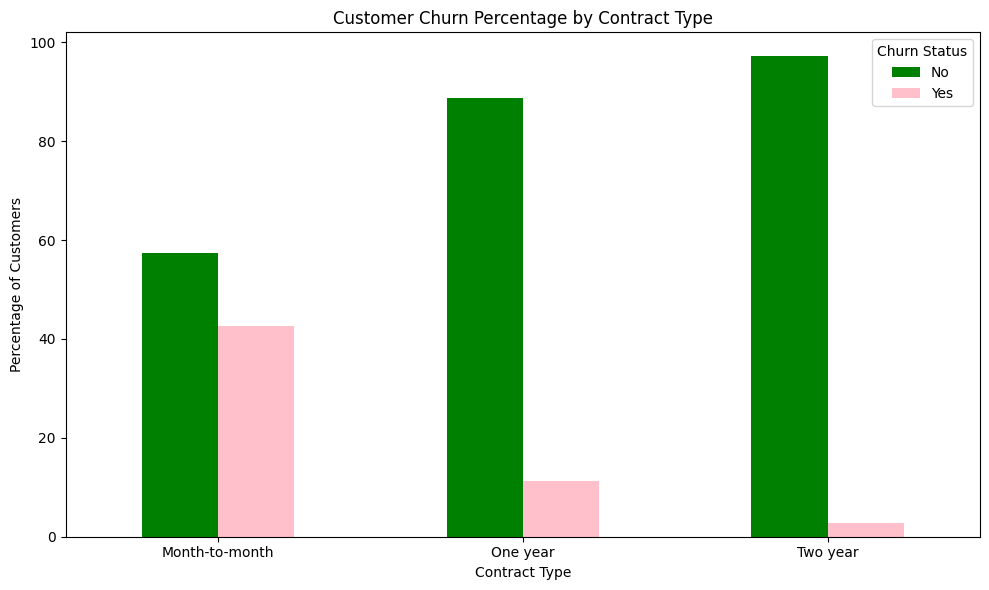

In [9]:
# Calculate churn percentages
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

# Plot grouped bar chart
contract_churn.plot(
    kind="bar",
    figsize=(10, 6),
    color=["green", "pink"]
)

plt.title("Customer Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

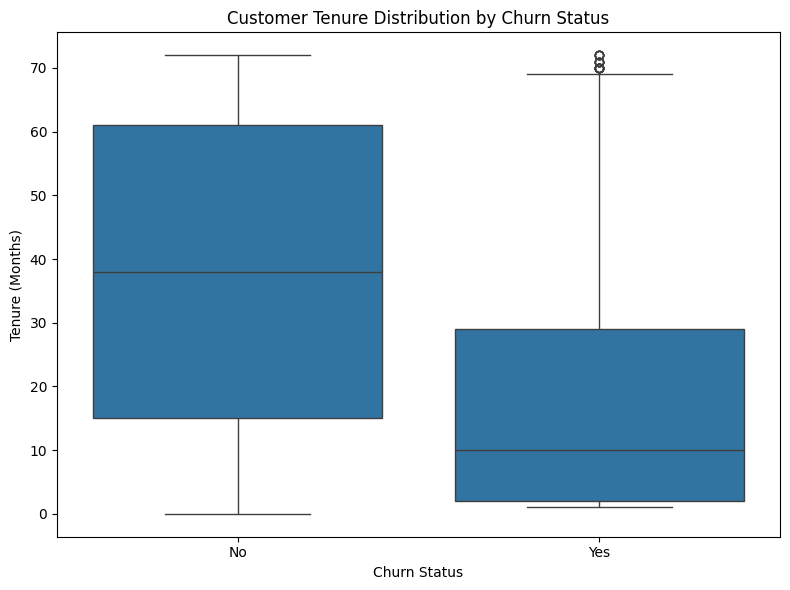

In [10]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure Distribution by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [11]:
print("Expected Frequencies:")
print(pd.DataFrame(
    expected,
    index=contract_table.index,
    columns=contract_table.columns
).round(2))

print("\nMinimum Expected Frequency:", round(expected.min(), 2))

Expected Frequencies:
Churn                No      Yes
Contract                        
Month-to-month  2846.69  1028.31
One year        1082.11   390.89
Two year        1245.20   449.80

Minimum Expected Frequency: 390.89
